# Semana 3 · Clasificación con vinos: árbol de decisión, KNN y SVM

**Prácticas y Herramientas de Big Data · UIDE**

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/carlosandresat/uide-big-data-online/blob/main/semana-03/ejemplos/clasificacion-vinos.ipynb)

**Cómo usar este notebook en Colab**
1. Ábrelo con el botón de arriba.
2. **Archivo → Guardar una copia en Drive.** Así puedes editarlo y tus cambios quedan en tu cuenta.
3. Ejecuta cada celda con **Shift + Enter**, en orden. La primera tarda unos segundos porque Colab enciende la máquina.

Las celdas marcadas con ✋ **Tu turno** son para que cambies algo y mires qué pasa. Las marcadas con 🔎 **Interpreta** son preguntas para pensar antes de seguir.

**Datos:** *Wine Quality* (vino tinto), de P. Cortez, A. Cerdeira, F. Almeida, T. Matos y J. Reis (2009), *Modeling wine preferences by data mining from physicochemical properties*, Decision Support Systems 47(4). Repositorio UCI, licencia CC BY 4.0. Son 1599 vinos portugueses con 11 medidas de laboratorio y un puntaje de 0 a 10 que dieron catadores.

## 1. Los datos

Cargamos el CSV (está separado por `;`, no por comas) y ponemos los nombres de las columnas en español.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import ConfusionMatrixDisplay

URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
COPIA = "https://raw.githubusercontent.com/carlosandresat/uide-big-data-online/main/semana-03/ejemplos/datos/winequality-red.csv"
try:
    vinos = pd.read_csv(URL, sep=";")
except Exception:                      # si el repositorio UCI no responde, usamos la copia del curso
    vinos = pd.read_csv(COPIA, sep=";")

vinos = vinos.rename(columns={
    "fixed acidity": "acidez_fija", "volatile acidity": "acidez_volatil", "citric acid": "acido_citrico",
    "residual sugar": "azucar_residual", "chlorides": "cloruros", "free sulfur dioxide": "so2_libre",
    "total sulfur dioxide": "so2_total", "density": "densidad", "pH": "ph", "sulphates": "sulfatos",
    "alcohol": "alcohol", "quality": "puntaje"})
print(vinos.shape)
vinos.head()

(1599, 12)


,acidez_fija,acidez_volatil,acido_citrico,azucar_residual,cloruros,so2_libre,so2_total,densidad,ph,sulfatos,alcohol,puntaje
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


Tres columnas que vamos a usar:

| Columna | Qué mide | Unidad |
|---|---|---|
| `alcohol` | grado alcohólico | % del volumen |
| `sulfatos` | sulfato de potasio, un aditivo | g/dm³ |
| `acidez_volatil` | ácido acético: en exceso, el vino sabe a vinagre | g/dm³ |

Antes de modelar, revisamos la calidad de los datos (semana 2): ¿hay faltantes o filas repetidas?

In [2]:
print("Faltantes:", vinos.isna().sum().sum())
print("Filas duplicadas:", vinos.duplicated().sum())
vinos = vinos.drop_duplicates()
print("Después de quitar duplicados:", vinos.shape)

Faltantes: 0
Filas duplicadas: 240
Después de quitar duplicados: (1359, 12)


Quitamos los duplicados porque, al separar entrenamiento y prueba, un mismo vino podría quedar en los dos lados: el modelo «reconocería» vinos que ya vio y su exactitud parecería mejor de lo que es.

**El objetivo.** Clasificar es predecir una **categoría**. Convertimos el puntaje en dos clases: **bueno** (6 o más) y **regular** (5 o menos). Las etiquetas existen: por eso es **aprendizaje supervisado**.

In [3]:
vinos["calidad"] = np.where(vinos["puntaje"] >= 6, "bueno", "regular")
print(vinos["puntaje"].value_counts().sort_index().to_dict())
vinos["calidad"].value_counts()

{3: 10, 4: 53, 5: 577, 6: 535, 7: 167, 8: 17}


calidad
bueno      719
regular    640
Name: count, dtype: int64

## 2. Árbol de decisión

Le pedimos a la IA: *«Entrena en Python un árbol de decisión que prediga si un vino es bueno o regular a partir de su alcohol, sus sulfatos y su acidez volátil, y muéstrame sus reglas»*. Antes de mirar su código, calculamos a mano la impureza del nodo raíz.

### 2.1 El índice de Gini de la raíz, a mano

**Gini = 1 − Σ pᵢ²**, donde pᵢ es la proporción de cada clase. Vale 0 si el nodo es puro y, con dos clases, como máximo 0,5 (mitad y mitad).

In [4]:
def gini(etiquetas):
    p = etiquetas.value_counts(normalize=True)   # proporciones, no conteos
    return 1 - (p ** 2).sum()

def entropia(etiquetas):
    p = etiquetas.value_counts(normalize=True)
    return -(p * np.log2(p)).sum()

y = vinos["calidad"]
print("Proporciones:", y.value_counts(normalize=True).round(3).to_dict())
print(f"Gini de la raíz:     {gini(y):.3f}")
print(f"Entropía de la raíz: {entropia(y):.3f}")

Proporciones: {'bueno': 0.529, 'regular': 0.471}
Gini de la raíz:     0.498
Entropía de la raíz: 0.998


🔎 **Interpreta.** El Gini de la raíz está casi en 0,5: las dos clases están casi mitad y mitad. El árbol tiene mucho por ordenar.

### 2.2 Lo que escribió la IA

In [5]:
PREDICTORAS = ["alcohol", "sulfatos", "acidez_volatil"]
X = vinos[PREDICTORAS]

arbol = DecisionTreeClassifier(criterion="gini", max_depth=2, random_state=0)
arbol.fit(X, y)
print(export_text(arbol, feature_names=PREDICTORAS, show_weights=True))
print(f"Gini de la raíz según scikit-learn: {arbol.tree_.impurity[0]:.3f}")

|--- alcohol <= 10.15
|   |--- sulfatos <= 0.57
|   |   |--- weights: [56.00, 237.00] class: regular
|   |--- sulfatos >  0.57
|   |   |--- weights: [160.00, 223.00] class: regular
|--- alcohol >  10.15
|   |--- alcohol <= 11.45
|   |   |--- weights: [281.00, 155.00] class: bueno
|   |--- alcohol >  11.45
|   |   |--- weights: [222.00, 25.00] class: bueno

Gini de la raíz según scikit-learn: 0.498


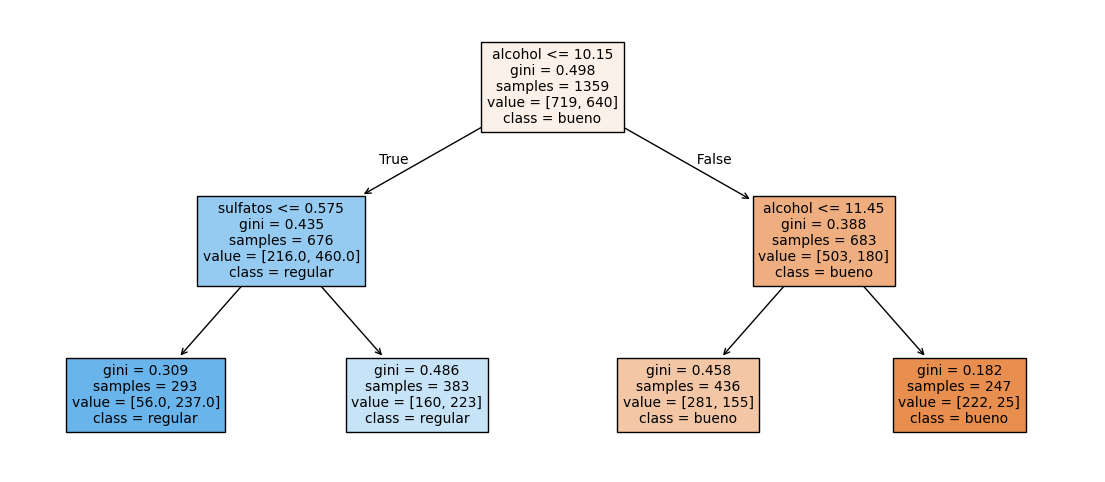

In [6]:
plt.figure(figsize=(14, 6))
plot_tree(arbol, feature_names=PREDICTORAS, class_names=arbol.classes_, filled=True, impurity=True, fontsize=10)
plt.show()

`weights: [bueno, regular]` son los vinos de cada clase que llegan a esa hoja. El umbral 10,15 es el punto medio entre dos valores de alcohol que existen en los datos.

### 2.3 Comprobamos la primera división

El árbol probó muchas divisiones y eligió la que deja los hijos **menos impuros en promedio**, ponderado por su tamaño: **Gini ponderado = Σ (tamaño del hijo ÷ tamaño del nodo) × Gini del hijo**.

In [7]:
umbral = arbol.tree_.threshold[0]
izq = y[vinos["alcohol"] <= umbral]
der = y[vinos["alcohol"] > umbral]
ponderado = len(izq) / len(y) * gini(izq) + len(der) / len(y) * gini(der)

print(f"alcohol <= {umbral:.2f}: {izq.value_counts().to_dict()}  Gini = {gini(izq):.3f}")
print(f"alcohol >  {umbral:.2f}: {der.value_counts().to_dict()}  Gini = {gini(der):.3f}")
print(f"Gini ponderado = {ponderado:.3f}  (la raíz tenía {gini(y):.3f})")

alcohol <= 10.15: {'regular': 460, 'bueno': 216}  Gini = 0.435
alcohol >  10.15: {'bueno': 503, 'regular': 180}  Gini = 0.388
Gini ponderado = 0.411  (la raíz tenía 0.498)


🔎 **Interpreta.**
- **La regla:** si el vino tiene más de 10,15 % de alcohol, el árbol dice «bueno»; si no, «regular».
- En el segundo nivel, las dos hojas de cada lado predicen **lo mismo**. Esas divisiones no cambian la respuesta: dejan hojas más puras (más seguras), pero la decisión ya la tomó el alcohol.
- La gran ventaja del árbol: **se lee y se dibuja**. Un enólogo puede discutir esta regla.

### 2.4 ¿Funciona con vinos nuevos? Sobreajuste y poda

Para saberlo, guardamos el 25 % de los vinos como **prueba**: el modelo no los ve al entrenar (lo profundizamos en la semana 4). Comparamos un árbol sin límite con árboles podados.

In [8]:
X_ent, X_pru, y_ent, y_pru = train_test_split(X, y, test_size=0.25, random_state=42)

modelos = {
    "sin límite":            DecisionTreeClassifier(random_state=0),
    "max_depth=3":           DecisionTreeClassifier(max_depth=3, random_state=0),
    "min_samples_leaf=20":   DecisionTreeClassifier(min_samples_leaf=20, random_state=0),
}
for nombre, modelo in modelos.items():
    modelo.fit(X_ent, y_ent)
    print(f"{nombre:<22} hojas = {modelo.get_n_leaves():>3}   "
          f"exactitud entrenamiento = {modelo.score(X_ent, y_ent):.3f}   prueba = {modelo.score(X_pru, y_pru):.3f}")

sin límite             hojas = 317   exactitud entrenamiento = 0.995   prueba = 0.688
max_depth=3            hojas =   8   exactitud entrenamiento = 0.739   prueba = 0.732
min_samples_leaf=20    hojas =  37   exactitud entrenamiento = 0.772   prueba = 0.750


🔎 **Interpreta.** Sin límite, el árbol crece hasta tener cientos de hojas y casi no se equivoca con los vinos que ya vio, pero acierta **menos** con los nuevos: **memorizó**, también el ruido. Eso es **sobreajuste**: un árbol demasiado complejo. **Podar** (limitar la profundidad o pedir un mínimo de vinos por hoja) lo simplifica y generaliza mejor.

✋ **Tu turno (4 minutos).** Cambia `min_samples_leaf` por 5, 50 y 100 (o `max_depth` por 1, 6 y 10) y ejecuta de nuevo. ¿Qué valor da la mejor exactitud en **prueba**? Escríbelo en el chat.

In [9]:
mi_arbol = DecisionTreeClassifier(min_samples_leaf=50, random_state=0)   # cambia este valor
mi_arbol.fit(X_ent, y_ent)
print(f"hojas = {mi_arbol.get_n_leaves()}   entrenamiento = {mi_arbol.score(X_ent, y_ent):.3f}   prueba = {mi_arbol.score(X_pru, y_pru):.3f}")

hojas = 15   entrenamiento = 0.747   prueba = 0.738


## 3. KNN: los K vecinos más cercanos

KNN clasifica un vino nuevo buscando los **K vinos más parecidos** (los más cercanos) y eligiendo la clase que más se repite entre ellos.

### 3.1 Primero, escalar

KNN mide distancias, así que todas las variables deben estar en la misma escala. `MinMaxScaler` lleva cada columna al rango 0–1. Se ajusta **solo con los datos de entrenamiento** (`fit`) y después se aplica a los dos conjuntos (`transform`): así el modelo no «ve» los datos de prueba. Es el paso que pide el Aprendizaje Autónomo 2.

In [10]:
escala = MinMaxScaler().fit(X_ent)
X_ent_e = escala.transform(X_ent)
X_pru_e = escala.transform(X_pru)

knn = KNeighborsClassifier(n_neighbors=15)
knn.fit(X_ent_e, y_ent)               # fit solo guarda los datos: aprendizaje «perezoso»
print("Vinos guardados por KNN:", knn.n_samples_fit_)

nuevo = pd.DataFrame({"alcohol": [11.0], "sulfatos": [0.70], "acidez_volatil": [0.40]})
print("Predicción para un vino nuevo:", knn.predict(escala.transform(nuevo))[0])

Vinos guardados por KNN: 1019
Predicción para un vino nuevo: bueno


### 3.2 ¿Qué K conviene?

In [11]:
for k in [1, 3, 5, 15, 31, 101, len(X_ent_e)]:
    m = KNeighborsClassifier(n_neighbors=k).fit(X_ent_e, y_ent)
    print(f"K = {k:>4}   entrenamiento = {m.score(X_ent_e, y_ent):.3f}   prueba = {m.score(X_pru_e, y_pru):.3f}")

K =    1   entrenamiento = 0.995   prueba = 0.706
K =    3   entrenamiento = 0.830   prueba = 0.721
K =    5   entrenamiento = 0.791   prueba = 0.729


K =   15   entrenamiento = 0.756   prueba = 0.759


K =   31   entrenamiento = 0.749   prueba = 0.744


K =  101   entrenamiento = 0.737   prueba = 0.741


K = 1019   entrenamiento = 0.533   prueba = 0.518


🔎 **Interpreta.**
- **K = 1** acierta casi todo en entrenamiento (cada vino es su propio vecino) y menos en prueba: **sobreajusta**.
- **K = todos** vota con todo el conjunto: siempre predice la clase más común. **Subajusta**.
- El mejor K está en medio y **se elige probando**. Aquí usamos los datos de prueba para ilustrarlo; lo correcto es elegirlo con datos de **validación**, que veremos la semana 4.
- **El costo:** como KNN solo guarda, todo el trabajo ocurre al predecir: una distancia a cada uno de los vinos guardados. Con millones de filas, cada predicción es lenta y ocupa mucha memoria.

### 3.3 La matriz de confusión (la pide el Aprendizaje Autónomo 2)

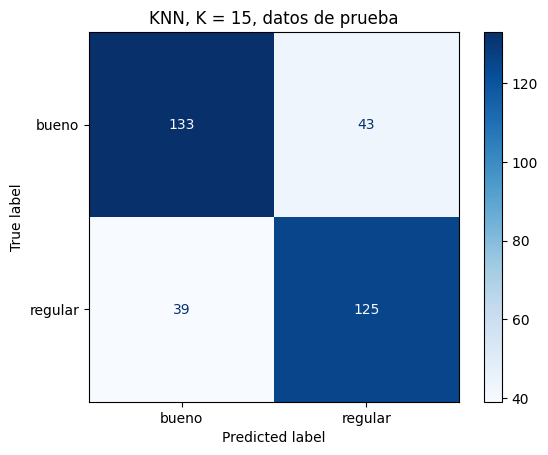

In [12]:
ConfusionMatrixDisplay.from_estimator(knn, X_pru_e, y_pru, cmap="Blues")
plt.title("KNN, K = 15, datos de prueba")
plt.show()

🔎 **Interpreta.** Las filas son la clase real y las columnas la que predijo el modelo. La diagonal son aciertos. ¿Qué error comete más: llamar «bueno» a un vino regular o al revés?

### 3.4 ¿Y si no escalamos?

Con las tres variables de arriba casi no se nota, porque tienen rangos parecidos. Con las 11 medidas sí: `so2_total` va de 6 a 289 y domina la distancia.

In [13]:
TODAS = vinos.columns[:11]
Xa_ent, Xa_pru, ya_ent, ya_pru = train_test_split(vinos[TODAS], y, test_size=0.25, random_state=42)

sin_escalar = KNeighborsClassifier(n_neighbors=15).fit(Xa_ent, ya_ent)
esc = MinMaxScaler().fit(Xa_ent)
con_escala = KNeighborsClassifier(n_neighbors=15).fit(esc.transform(Xa_ent), ya_ent)
print(f"11 variables sin escalar: prueba = {sin_escalar.score(Xa_pru, ya_pru):.3f}")
print(f"11 variables escaladas:   prueba = {con_escala.score(esc.transform(Xa_pru), ya_pru):.3f}")

11 variables sin escalar: prueba = 0.641
11 variables escaladas:   prueba = 0.750


## 4. SVM: el margen más ancho

SVM busca el **hiperplano** (una recta en 2D, un plano en 3D) que separa las clases dejando el **margen más ancho** hasta los puntos más cercanos de cada clase, los **vectores de soporte**. Si una recta no alcanza, un ***kernel*** lleva los datos a un espacio de más dimensiones donde una frontera plana sí los separa.

### 4.1 Con los vinos

In [14]:
for kernel in ["linear", "rbf"]:
    svm = SVC(kernel=kernel).fit(X_ent_e, y_ent)
    print(f"SVM {kernel:<6}  prueba = {svm.score(X_pru_e, y_pru):.3f}   vectores de soporte = {svm.n_support_.sum()}")

SVM linear  prueba = 0.747   vectores de soporte = 685
SVM rbf     prueba = 0.753   vectores de soporte = 602


🔎 **Interpreta.** El *kernel* RBF casi no mejora: en estos vinos la frontera entre «bueno» y «regular» es casi lineal (más alcohol, mejor). Además, más de la mitad de los 1019 vinos de entrenamiento son vectores de soporte: las clases se mezclan mucho cerca de la frontera. Con datos de laboratorio, ningún modelo pasa de ~75 %: el puntaje lo dan personas al catar.

### 4.2 Donde el *kernel* sí importa

Dos círculos, uno dentro del otro: ninguna recta los separa.

SVM lineal           prueba = 0.45
SVM con kernel RBF   prueba = 1.00
KNN, K = 5           prueba = 1.00


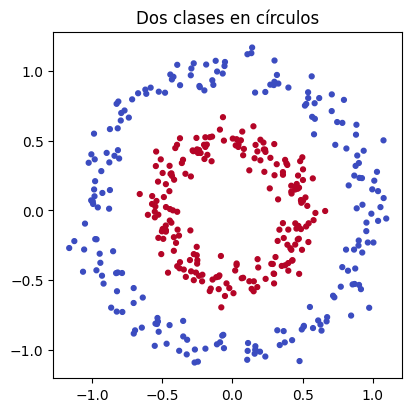

In [15]:
from sklearn.datasets import make_circles

Xc, yc = make_circles(n_samples=400, noise=0.08, factor=0.5, random_state=0)
Xc_ent, Xc_pru, yc_ent, yc_pru = train_test_split(Xc, yc, test_size=0.25, random_state=42)

for nombre, modelo in {"SVM lineal": SVC(kernel="linear"), "SVM con kernel RBF": SVC(kernel="rbf"),
                       "KNN, K = 5": KNeighborsClassifier(n_neighbors=5)}.items():
    modelo.fit(Xc_ent, yc_ent)
    print(f"{nombre:<20} prueba = {modelo.score(Xc_pru, yc_pru):.2f}")

plt.figure(figsize=(4.5, 4.5))
plt.scatter(Xc[:, 0], Xc[:, 1], c=yc, cmap="coolwarm", s=12)
plt.title("Dos clases en círculos")
plt.show()

## 5. Árbol, KNN o SVM

| | Árbol de decisión | KNN | SVM |
|---|---|---|---|
| **Cómo decide** | preguntas que reducen la impureza | voto de los K vecinos | lado del hiperplano |
| **Entrenar** | rápido | solo guarda los datos | lento con muchos datos |
| **Predecir** | muy rápido | lento con muchos datos | rápido |
| **A favor** | se interpreta; numéricos y categóricos | simple, sin supuestos | alta dimensión; no lineal con *kernel* |
| **Cuidado** | crece sin límite: podar | escalar; K pequeño sobreajusta | escalar; elegir el *kernel* |

Ninguno es siempre el mejor: se comparan con datos de prueba. Los tres son **supervisados**: aprenden de ejemplos con etiqueta.

## 6. ✋ Ejercicio individual (si ves la grabación, o para practicar)

1. En la sección 2.4, encuentra el `min_samples_leaf` con mejor exactitud en prueba entre 5, 20, 50 y 100.
2. En la sección 3.2, ¿qué K da la mejor exactitud en prueba? Agrega K = 21 y K = 51 a la lista.
3. **Para el Aprendizaje Autónomo 2:** repite las secciones 1 a 3 con **tu dataset** del Aprendizaje Autónomo 1. Usa tu variable categórica como objetivo y dos o más numéricas como predictoras. Si tienes texto en las predictoras, el árbol falla (`could not convert string to float`): usa solo numéricas o codifícalas con `pd.get_dummies`.

## Anexo · Las cuentas de la presentación (12 estudiantes)

El ejemplo pequeño que hicimos a mano en la sesión, para comprobarlo.

In [16]:
est = pd.DataFrame({
    "horas":      [1, 2, 2, 3, 4, 5, 5, 6, 7, 8, 9, 10],
    "asistencia": [60, 85, 50, 90, 88, 95, 65, 80, 75, 90, 85, 95],
    "aprueba":    ["no", "no", "no", "sí", "no", "sí", "no", "sí", "sí", "sí", "sí", "sí"],
})
a = DecisionTreeClassifier(max_depth=2, random_state=0).fit(est[["horas", "asistencia"]], est["aprueba"])
print(export_text(a, feature_names=["horas", "asistencia"]))
izq, der = est.aprueba[est.horas <= 5.5], est.aprueba[est.horas > 5.5]
print(f"Gini raíz = {gini(est.aprueba):.3f} · ponderado de horas <= 5,5 = {(len(izq) * gini(izq) + len(der) * gini(der)) / 12:.3f}")

# KNN: ¿aprueba quien estudia 5 horas y asiste al 85 %?
e = MinMaxScaler().fit(est[["horas", "asistencia"]])
nueva = e.transform(pd.DataFrame({"horas": [5], "asistencia": [85]}))
est["distancia"] = np.sqrt(((e.transform(est[["horas", "asistencia"]]) - nueva) ** 2).sum(axis=1)).round(3)
print(est.sort_values("distancia").head(5).to_string(index=False))
for k in (1, 3, 5):
    m = KNeighborsClassifier(n_neighbors=k).fit(e.transform(est[["horas", "asistencia"]]), est["aprueba"])
    print(f"K = {k}: predice «{m.predict(nueva)[0]}»")

|--- horas <= 5.50
|   |--- asistencia <= 89.00
|   |   |--- class: no
|   |--- asistencia >  89.00
|   |   |--- class: sí
|--- horas >  5.50
|   |--- class: sí



Gini raíz = 0.486 · ponderado de horas <= 5,5 = 0.238
 horas  asistencia aprueba  distancia
     4          88      no      0.130
     6          80      sí      0.157
     5          95      sí      0.222
     3          90      sí      0.248
     7          75      sí      0.314
K = 1: predice «no»
K = 3: predice «sí»
K = 5: predice «sí»
